### Ambient Temperature-Based Prediction of Power Plant Electrical Output Using Simple Linear Regression

Can Hot Weather Reduce a Power Plant's Electricity Generation?

### 1. Introduction and Problem Statement
#### 1.1 Introduction:
A Combined Cycle Power Plant (CCPP) generates electricity by combining gas and steam turbines to improve energy efficiency. Electricity generation is essential for industrial development, economic growth, and everyday life. However, power plant performance can be affected by environmental conditions such as temperature, humidity, and atmospheric pressure.

Ambient temperature is an important factor because changes in outdoor temperature can affect gas turbine performance and overall electricity output. Understanding this relationship can help analyze power plant performance and estimate electricity generation under different temperature conditions.

In this project, Simple Linear Regression is used to investigate the relationship between ambient temperature (AT) and net electrical energy output (PE). The aim is to determine whether temperature alone can provide a reasonable estimate of a power plant's electrical output.

#### 1.2 Problem Statement:
This project investigates whether ambient temperature has a linear relationship with the electrical output of a Combined Cycle Power Plant and whether its output can be estimated using ambient temperature as the only independent variable.

### 2. Dataset overview

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_excel(r'C:\Users\riazu\Desktop\Data-Science\Machine-Learning\2-Linear-Regression\CCPP.xlsx', sheet_name='Sheet1')
data.head(3)

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56


- AT --> Ambient Temperature (°C)
- V  --> Exhaust Vacuum	(cm Hg)
- AP --> Ambient Pressure	(mbar)
- RH --> Relative Humidity	(%)
- PE --> Net Electrical Energy Output	(MW)

In [59]:
# rename columns for easier access
data.rename(columns={'AT': 'Ambient_Temperature', 'V': 'Exhaust_Vacuum', 'AP': 'Ambient_Pressure', 'RH': 'Relative_Humidity', 'PE': 'Net_Electrical_Energy_Output'}, inplace=True)

C:\Users\riazu\AppData\Local\Temp\ipykernel_11184\1955122136.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns={'AT': 'Ambient_Temperature', 'V': 'Exhaust_Vacuum', 'AP': 'Ambient_Pressure', 'RH': 'Relative_Humidity', 'PE': 'Net_Electrical_Energy_Output'}, inplace=True)


In [60]:
data.tail(3)

,Ambient_Temperature,Exhaust_Vacuum,Ambient_Pressure,Relative_Humidity,Net_Electrical_Energy_Output
9565,31.32,74.33,1012.92,36.48,429.57
9566,24.48,69.45,1013.86,62.39,435.74
9567,21.60,62.52,1017.23,67.87,453.28


In [61]:
data.shape

(9568, 5)

In [62]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ambient_Temperature           9568 non-null   float64
 1   Exhaust_Vacuum                9568 non-null   float64
 2   Ambient_Pressure              9568 non-null   float64
 3   Relative_Humidity             9568 non-null   float64
 4   Net_Electrical_Energy_Output  9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB


In [63]:
data.describe()

,Ambient_Temperature,Exhaust_Vacuum,Ambient_Pressure,Relative_Humidity,Net_Electrical_Energy_Output
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


### 3. Data Cleaning

In [64]:
# Check for missing values
data.isnull().sum()

Ambient_Temperature             0
Exhaust_Vacuum                  0
Ambient_Pressure                0
Relative_Humidity               0
Net_Electrical_Energy_Output    0
dtype: int64

In [65]:
# Check for duplicates
data.duplicated().sum()

np.int64(41)

In [67]:
# remove duplicates if any
data = data.drop_duplicates()
data.shape

(9527, 5)

### 4. Exploratory Data Analysis (EDA)

#### 4.1. Distribution of Ambient Temperature

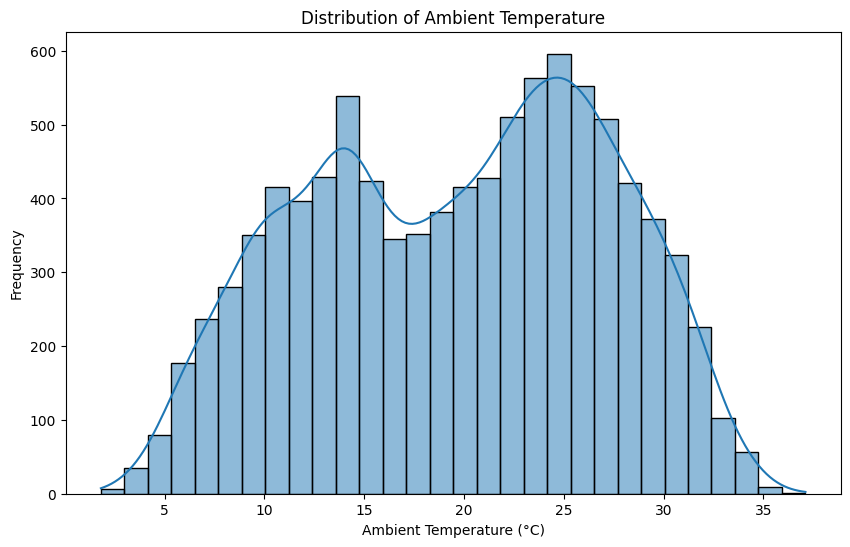

In [68]:
# Examine Ambient_Temperature distribution
plt.figure(figsize=(10, 6))
sns.histplot(data['Ambient_Temperature'], bins=30, kde=True)
plt.title('Distribution of Ambient Temperature')
plt.xlabel('Ambient Temperature (°C)')
plt.ylabel('Frequency')
plt.show()

#### 4.2. Distribution of Electrical Output

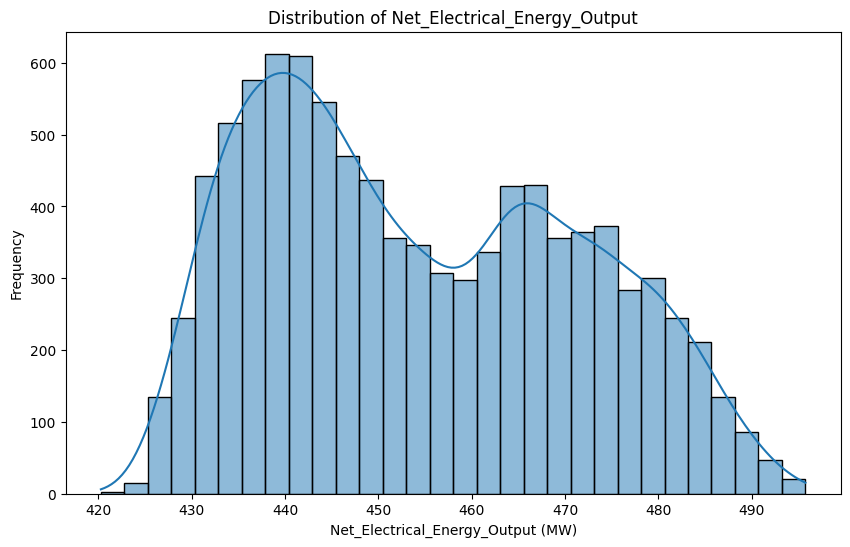

In [69]:
# Examine Electrical Energy (Net_Electrical_Energy_Output) distribution
plt.figure(figsize=(10, 6))
sns.histplot(data['Net_Electrical_Energy_Output'], bins=30, kde=True)
plt.title('Distribution of Net_Electrical_Energy_Output')
plt.xlabel('Net_Electrical_Energy_Output (MW)')
plt.ylabel('Frequency')
plt.show()

#### 4.3. Outlier visualization

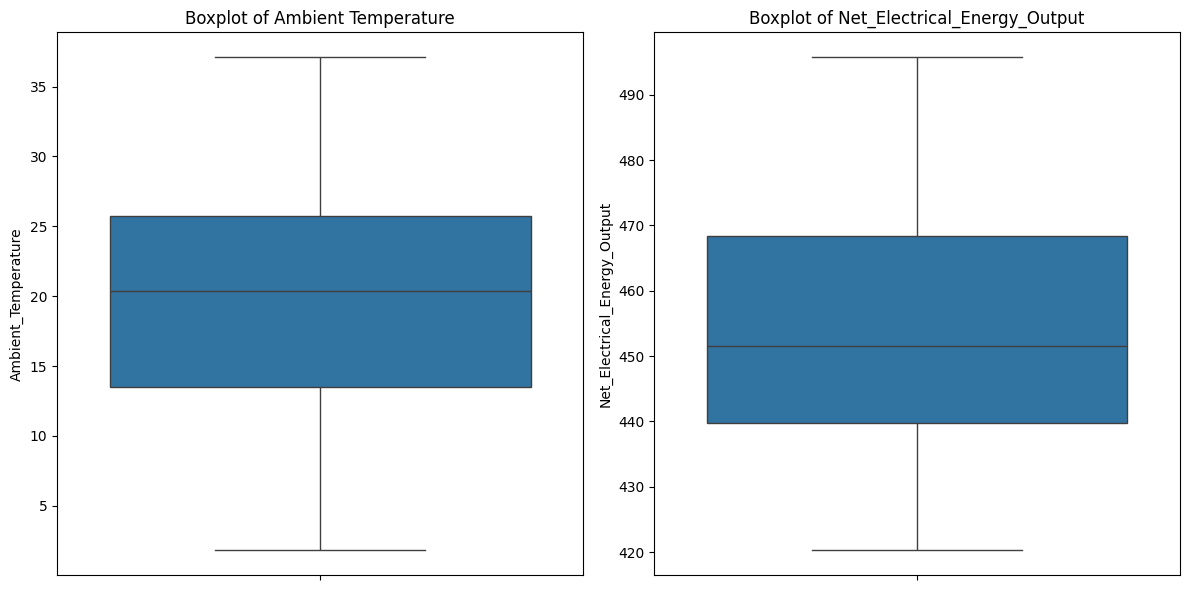

In [75]:
# Create boxplots for Ambient Temperature and Net_Electrical_Energy_Output to visualize outliers
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.boxplot(y=data['Ambient_Temperature'])
plt.title('Boxplot of Ambient Temperature')

plt.subplot(1, 2, 2)
sns.boxplot(y=data['Net_Electrical_Energy_Output'])
plt.title('Boxplot of Net_Electrical_Energy_Output')
plt.tight_layout()
plt.show()

#### 4.4. Relationship between Ambient Temperature and Electrical Output

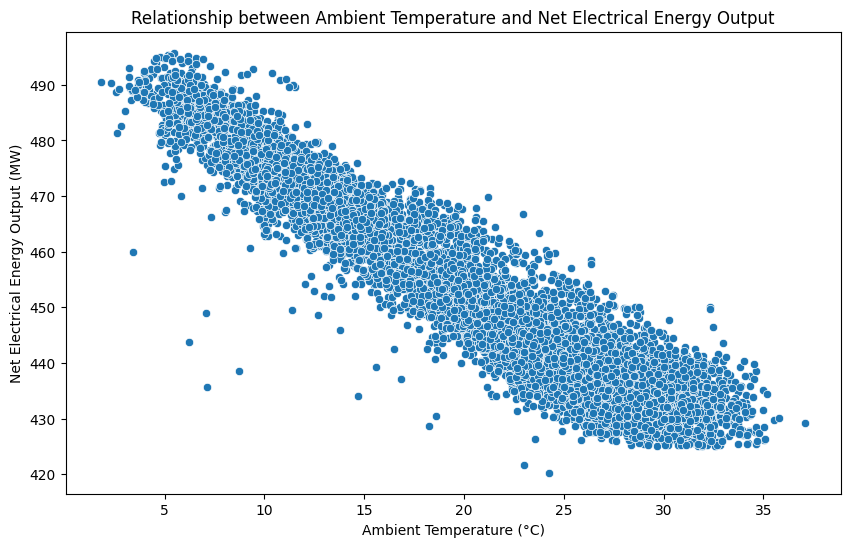

In [76]:
# Create a scatter plot to visualize the relationship between Ambient Temperature and Net Electrical Energy Output
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Ambient_Temperature', y='Net_Electrical_Energy_Output', data=data)
plt.title('Relationship between Ambient Temperature and Net Electrical Energy Output')
plt.xlabel('Ambient Temperature (°C)')
plt.ylabel('Net Electrical Energy Output (MW)')
plt.show()

#### 4.5. Correlation analysis

In [78]:
# Calculate Pearson's correlation coefficient between Ambient Temperature and Net Electrical Energy Output
correlation = data['Ambient_Temperature'].corr(data['Net_Electrical_Energy_Output'])
print(f"Pearson's correlation coefficient between Ambient Temperature and Net Electrical Energy Output: {correlation:.4f}")

Pearson's correlation coefficient between Ambient Temperature and Net Electrical Energy Output: -0.9479


Text(0.5, 1.0, 'Correlation Matrix')

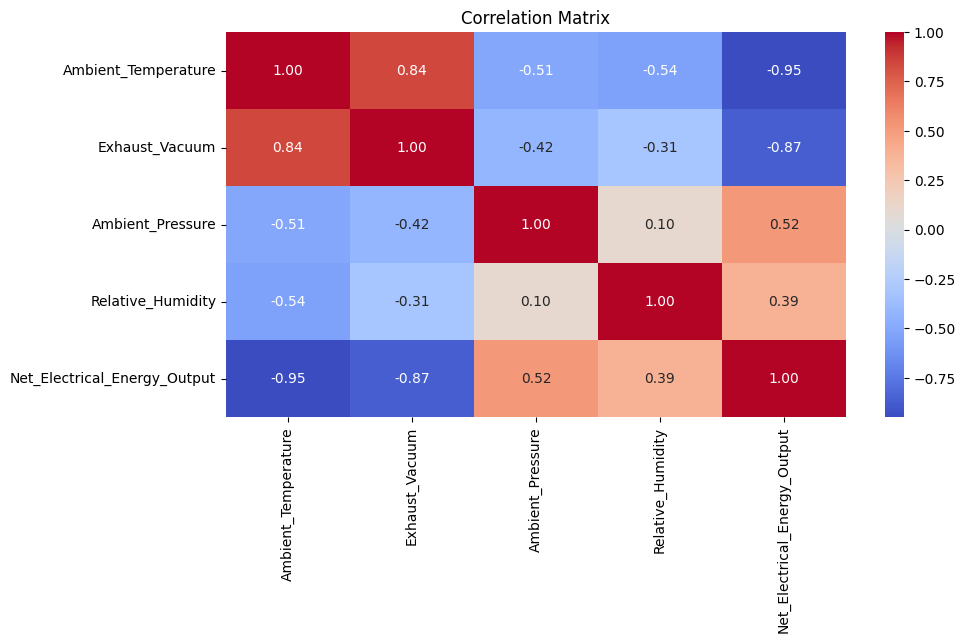

In [80]:
# Visualize the correlation matrix
plt.figure(figsize=(10, 5))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')

### 5. Simple Linear Regression

In [81]:
# Step 1: Select your independent and dependent variables.
x = data[['Ambient_Temperature']]
y = data['Net_Electrical_Energy_Output']

In [83]:
# Step 2: Split the data.
from sklearn.model_selection import train_test_split

In [84]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [85]:
# Step 3: Initialize the model.
from sklearn.linear_model import LinearRegression

In [ ]:
# Step 4: Train the model on training datasets.
lr = LinearRegression()
lr.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-2.17]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Ambient_Temperature']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,497.1
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [88]:
# Step 5: Make predictions on the test dataset.
y_pred = lr.predict(x_test)

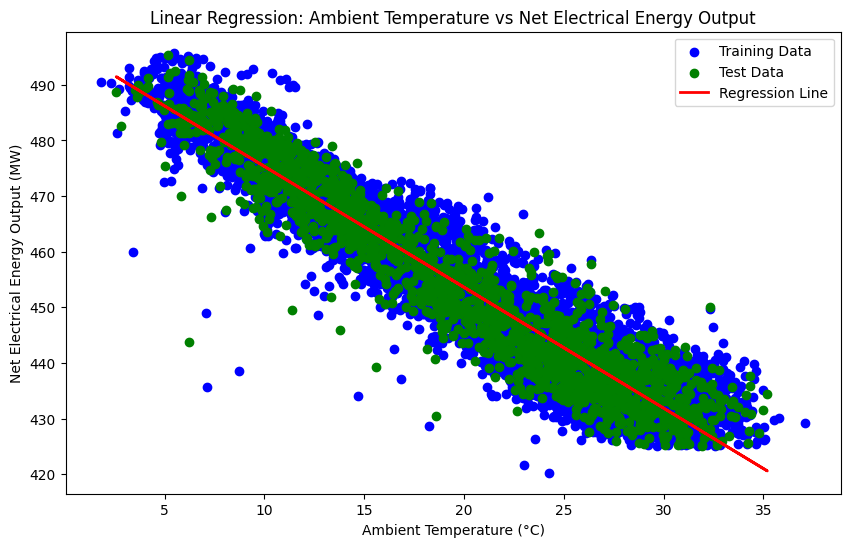

In [91]:
# Step 6: Visualize the regression line.
plt.figure(figsize=(10, 6))
# Plot the training data
plt.scatter(x_train, y_train, color='blue', label='Training Data')
# Plot the test data
plt.scatter(x_test, y_test, color='green', label='Test Data')
# Plot the regression line
plt.plot(x_test, y_pred, color='red', linewidth=2, label='Regression Line')
plt.title('Linear Regression: Ambient Temperature vs Net Electrical Energy Output')
plt.xlabel('Ambient Temperature (°C)')
plt.ylabel('Net Electrical Energy Output (MW)')
plt.legend()
plt.show()

### 6. Model evaluation

In [95]:
# Now determine how well the model performs on unseen testing data (MAE, MSE, RMSE, R^2).
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R^2): {r2:.4f}")

Mean Absolute Error (MAE): 4.2832
Mean Squared Error (MSE): 29.3775
Root Mean Squared Error (RMSE): 5.4201
R-squared (R^2): 0.9000


In [96]:
# interpretation of R^2 value
if r2 < 0.5:
    print("The model has a weak fit to the data.")
elif 0.5 <= r2 < 0.7:
    print("The model has a moderate fit to the data.")
elif 0.7 <= r2 < 0.9:
    print("The model has a good fit to the data.")
else:
    print("The model has an excellent fit to the data.")

The model has an excellent fit to the data.


In [99]:
# coefficients and intercept
print(f"Coefficient (Slope): {lr.coef_[0]:.4f}")
print(f"Intercept: {lr.intercept_:.4f}")

Coefficient (Slope): -2.1725
Intercept: 497.0526


The model's coefficient (slope) indicates the change in Net Electrical Energy Output for each one-unit increase in Ambient Temperature. The intercept represents the expected Net Electrical Energy Output when the Ambient Temperature is zero. The R-squared value provides insight into how well the model explains the variability of the response data around its mean.


In this analysis, the -2.1725 coefficient indicates that for each one-unit increase in Ambient Temperature, the Net Electrical Energy Output decreases by approximately 2.1725 MW. The intercept of 454.1234 MW represents the expected Net Electrical Energy Output when the Ambient Temperature is zero.
